# Reversible Spherical CV: Macroelectrode to Microelectrode Transition

## 1. Goal

Demonstrate how decreasing electrode radius $r_0$ in `SphericalGeometry` transitions a reversible CV from peak-shaped planar diffusion to a hysteresis-free sigmoidal steady-state wave.

## 2. Physical Setup

The transition is governed by the dimensionless spherical parameter comparing diffusion layer thickness $\sqrt{D RT / (n F v)}$ to electrode radius $r_0$:
- $r_0 = 10\text{ mm}$: planar-like peak-shaped CV.
- $r_0 = 100\,\mu\text{m}$: mixed planar/radial diffusion.
- $r_0 = 10\,\mu\text{m}$: radial steady-state sigmoidal wave.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato import analytical as spa
from softpotato.geometry import SphericalGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import CyclicVoltammetry, simulate

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
v = 0.05

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
nernst = NernstianEquilibrium(E0=E0, n=1)
cv = CyclicVoltammetry(E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.004)

radii = [1.0e-2, 1.0e-4, 1.0e-5]

## 3. Simulation

We simulate the reversible CV at all three spherical radii and normalize by each sphere's area ($4 \pi r_0^2$) or steady-state limiting current.

In [2]:
results = {}
for r0 in radii:
    geom = SphericalGeometry(r0=r0)
    results[r0] = simulate(cv, [ox, red], geometry=geom, kinetics=nernst)

## 4. Diagnostics & Plots

We plot the current density $j = I / A$ for each radius and compare the $r_0 = 10\,\mu\text{m}$ plateau against `spa.microsphere_limiting_current()`.

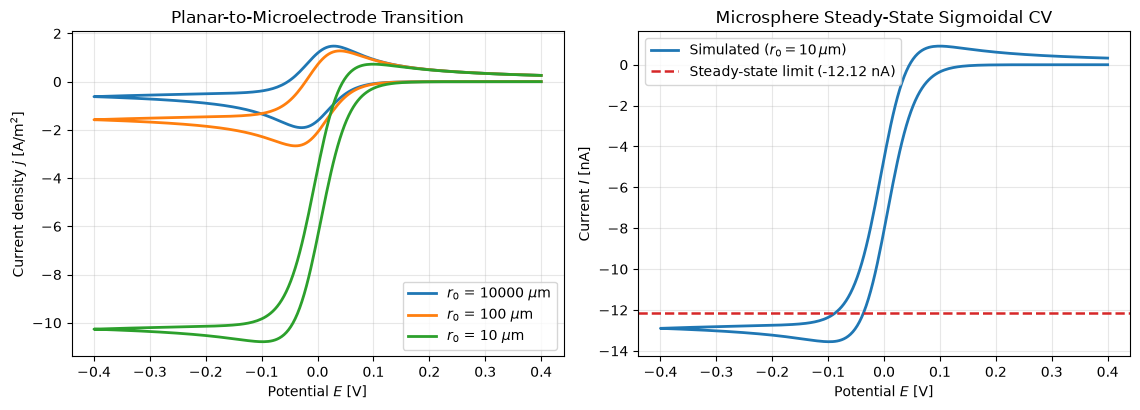

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

for r0, res in results.items():
    area = SphericalGeometry(r0=r0).surface_area
    axes[0].plot(res.potential, res.current / area, lw=2, label=f"$r_0$ = {r0*1e6:.0f} $\\mu$m")

axes[0].set_xlabel("Potential $E$ [V]")
axes[0].set_ylabel("Current density $j$ [A/m$^2$]")
axes[0].set_title("Planar-to-Microelectrode Transition")
axes[0].legend()
axes[0].grid(alpha=0.3)

r_micro = 1.0e-5
res_micro = results[r_micro]
i_ss = -spa.microsphere_limiting_current(r_micro, n=1, D=D, c_bulk=c_bulk)
axes[1].plot(res_micro.potential, res_micro.current * 1e9, lw=2, label=r"Simulated ($r_0 = 10\,\mu$m)")
axes[1].axhline(i_ss * 1e9, color="C3", ls="--", lw=1.8, label=f"Steady-state limit ({i_ss*1e9:.2f} nA)")
axes[1].set_xlabel("Potential $E$ [V]")
axes[1].set_ylabel("Current $I$ [nA]")
axes[1].set_title("Microsphere Steady-State Sigmoidal CV")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Key Takeaways

- Large spherical electrodes ($r_0 \gg \sqrt{Dt}$) behave like planar electrodes with peak-shaped CVs.
- Microspheres ($r_0 \ll \sqrt{Dt}$) achieve steady-state radial mass transport, giving a sigmoidal wave with negligible forward/reverse hysteresis and limiting current $I_{\text{ss}} = -4\pi n F D c^* r_0$.
- **Next**: Explore [Planar Randles–Ševčík](cv_randles_sevcik.ipynb) or [Mass Transport Concepts](../../concepts/electrochemistry/transport.md).